In [1]:
from pycalphad import Workspace, Database, variables as v
from pycalphad.property_framework import IsolatedPhase, ModelComputedProperty
import matplotlib.pyplot as plt
import numpy as np

In [13]:
# Coherent Spinodal 
# This is my modified bond model function that also calculates the derivatives; it requires the dependent component to be specified
import pandas as pd

def add_lattice_parameter_BCC(dataset: pd.DataFrame, elements: list[str], dependent_component) -> pd.DataFrame:
    '''https://github.com/tandocca/Lattice-Parameter/blob/main/README.md'''
    from itertools import product
    from math import sqrt
    
    B2_bond_lengths = { 
    "HfHf": 3.0673656116191044,
    "HfNb": 2.9572441802697935,
    "HfTi": 2.9445255192919726,
    "HfV":  2.844887616911763,
    "NbHf": 2.9572441802697935,
    "NbNb": 2.861885570144507,
    "NbTi": 2.8249641822131335,
    "NbV":  2.737275009925361,
    "TiHf": 2.9445255192919726,
    "TiNb": 2.8249641822131335,
    "TiTi": 2.810474121277211,
    "TiV":  2.6985800750769795,
    "VHf":  2.844887616911763,
    "VNb":  2.737275009925361,
    "VTi":  2.6985800750769795,
    "VV":   2.591424330622251,
    }
    
    lp_values = []
    
    independent_elements = [x for x in elements if x != dependent_component]
    
    lp_grad = {key: [] for key in independent_elements}
    

    for _, row in dataset.iterrows():
        avg_bond = 0.0
        fractions = row[elements].to_dict()

        for e1, e2 in product(elements, repeat=2):
            pair_key = "".join([e1,e2])
            if pair_key not in B2_bond_lengths:
                # optionally handle missing keys (skip or raise)
                continue
            c_pair = fractions[e1] * fractions[e2]
            avg_bond += B2_bond_lengths[pair_key] * c_pair
        
        for key in lp_grad:
            derivative = 0
            for e1, e2 in product(independent_elements, [key]):
                pair_key = "".join([e1,e2])
                if pair_key not in B2_bond_lengths:
                    # optionally handle missing keys (skip or raise)
                    continue
                # 2/sqrt(3)*(2*x_i*d_ik)
                derivative += 4*fractions[e1]*B2_bond_lengths[pair_key]/sqrt(3)
                
            el_list = [x for x in independent_elements if x != key]
                
            for e1, e2 in product(el_list, [dependent_component]):
                derivative += -4*fractions[e1]*B2_bond_lengths[pair_key]/sqrt(3)
            
            derivative += 4*(fractions[dependent_component]-fractions[key])*B2_bond_lengths["".join([dependent_component,key])]/sqrt(3)
            derivative += -4*fractions[dependent_component]*B2_bond_lengths["".join([dependent_component,dependent_component])]/sqrt(3)
            
            lp_grad[key].append(derivative)

        # Compute lattice parameter for BCC structure: a = 2*d111/sqrt(3)
        lp = round((2 / sqrt(3)) * avg_bond,4)
        lp_values.append(lp)

    dataset['pred_a_bcc_DFT_(A)'] = lp_values
    for key in lp_grad:
        dataset['da/dx_'+key] = lp_grad[key]
    
    return dataset

def change_directory_to_current_py_file():
    try:
        import os
        os.chdir(os.path.split(os.path.abspath(__file__))[0])
    except Exception as e:
        print(f'\nDirectory change or os module error:\n\n{e}')

change_directory_to_current_py_file()

def import_data(file_name: str) -> pd.DataFrame:
    import os
    csv_file = f"{file_name}.csv"
    if os.path.exists(csv_file):
        data = pd.read_csv(csv_file)
        return data
    
    with pd.ExcelFile(f"{file_name}.xlsx") as xlsx:
        sheet_names = xlsx.sheet_names
        data = pd.read_excel(xlsx, sheet_name=sheet_names[0])
    data = data.filter(regex='^(?!Unnamed|Index)')
    # data.to_csv(csv_file, index=False)  # Save as CSV for future use
    return data

def extract_elements(data: pd.DataFrame) -> list[str]:
    elements = [col for col in data.columns if len(col) <= 2]
    return elements

file_name = 'sqs_elastic_constants_HfNbVTi'
dataset: pd.DataFrame = import_data(f'{file_name}')
elements = ['Hf', 'Nb', 'Ti', 'V']
dependent_component = 'V'
# elements = extract_elements(dataset) # alternatively
dataset: pd.DataFrame = add_lattice_parameter_BCC(dataset, elements,dependent_component)

dataset


Directory change or os module error:

name '__file__' is not defined


,Hf,Nb,V,Ti,m_Hf,m_Nb,m_V,m_Ti,a_relaxed_A,C11_GPa,...,youngs_modulus_GPa,bulk_modulus_vrh_GPa,shear_modulus_vrh_GPa,poisson_ratio,biaxial_modulus_M_GPa,sqs_objective,pred_a_bcc_DFT_(A),da/dx_Hf,da/dx_Nb,da/dx_Ti
0,0.00,0.00,0.00,1.00,0,0,0,128,3.245874,104.878682,...,12.699366,111.113028,4.287571,0.480951,24.466617,0.000000,3.2453,0.000000,0.000000,0.258408
1,0.00,0.00,0.05,0.95,0,0,6,122,3.248687,181.205021,...,131.026142,119.221541,49.750553,0.316831,191.791698,0.014572,3.2323,0.029267,0.016841,0.257861
2,0.00,0.00,0.10,0.90,0,0,13,115,3.236491,169.599081,...,114.578186,120.153364,42.719047,0.341067,173.884360,0.007135,3.2195,0.058535,0.033683,0.257314
3,0.00,0.00,0.15,0.85,0,0,19,109,3.224490,180.382765,...,133.224511,121.661748,50.559844,0.317493,195.198830,0.013842,3.2066,0.087802,0.050524,0.256767
4,0.00,0.00,0.20,0.80,0,0,26,102,3.207127,163.827698,...,99.743759,123.871094,36.514874,0.365796,157.274008,0.004022,3.1938,0.117070,0.067366,0.256220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1766,0.90,0.10,0.00,0.00,115,13,0,0,3.532887,196.447736,...,147.383181,117.682411,57.069085,0.291270,207.953884,0.007135,3.5166,0.465349,0.303716,0.281967
1767,0.95,0.00,0.00,0.05,122,0,0,6,3.542687,205.563980,...,169.270363,114.408367,67.523831,0.253412,226.725275,0.014572,3.5277,0.488101,0.290213,0.307020
1768,0.95,0.00,0.05,0.00,122,0,6,0,3.534637,197.669452,...,158.046403,112.936396,62.382047,0.266762,215.545822,0.014572,3.5161,0.517369,0.307055,0.306473
1769,0.95,0.05,0.00,0.00,122,6,0,0,3.543538,181.847404,...,150.865624,112.631723,59.081584,0.276757,208.595969,0.014572,3.5292,0.489570,0.304602,0.295773


In [14]:
# Each composition from the dataset is set as conditions for the equilibrium calculation. First derivatives of the chemical potential of each component
# are calculated with respect to the three independent composition variables. The second derivatives of the Gibbs energy with respect to the independent
# composition variables are then calculated using the relation dG/dxA = muA - muB where B is the dependent component. 
# Thus, d^2G/dxAdxA = dmuA/dxA - dmuB/dxA. The Hessian is built from its individual components, and some fancy linear algebra is done to transform from 
# a simplex space to a cartesian space so that we do the eigenanalysis in space where the eigenvectors are actually orthogonal. The "O" matrix comes from
# Table 1 in Kadirvel et al., Scripta Materialia. (2022). 
import pandas as pd

eigenvalue_1 = []
eigenvalue_2 = []
eigenvalue_3 = []

eigenvalue_1_chem = []
eigenvalue_2_chem = []
eigenvalue_3_chem = []

drop_list = []
T = 600
# changed column titles to have the second letter lowercase here as well
for row, cols in dataset.iterrows():
    print(row)
    wks = Workspace(database=Database('HfNbVTi.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): dataset.loc[row, 'Hf'],v.X('NB'): dataset.loc[row, 'Nb'], v.X('TI'): dataset.loc[row, 'Ti'], v.T: T, v.P: 101325})

    try:
        dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
        dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
        dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
        dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

        dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
        dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
        dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
        dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

        dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
        dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
        dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
        dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

        d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
        d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
        d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

        d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
        d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
        d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

        d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
        d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
        d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI
        #this is now the chemical Hessian
        chem_Hessian = np.array([[d2G_dxHFdxHF, d2G_dxHFdxNB, d2G_dxHFdxTI], [d2G_dxNBdxHF, d2G_dxNBdxNB, d2G_dxNBdxTI], [d2G_dxTIdxHF, d2G_dxTIdxNB, d2G_dxTIdxTI]])
        #this is the eta vector 1/a*da/dx
        eta = np.array([[1/dataset.loc[row, 'pred_a_bcc_DFT_(A)']*dataset.loc[row, 'da/dx_Hf'],1/dataset.loc[row, 'pred_a_bcc_DFT_(A)']*dataset.loc[row, 'da/dx_Nb'],1/dataset.loc[row, 'pred_a_bcc_DFT_(A)']*dataset.loc[row, 'da/dx_Ti']]])
        c11 = dataset.loc[row,'C11_GPa']*1e9
        c12 = dataset.loc[row,'C12_GPa']*1e9
        c44 = dataset.loc[row,'C44_GPa']*1e9
        lattice_param = dataset.loc[row, 'pred_a_bcc_DFT_(A)']
        #V=a^3*N_A/2
        V = (lattice_param*1e-10)**3*6.022e23/2
        #coherent contribution
        if 2*c44 - c11 + c12 > 0:
            Y = (c11+2*c12)*(c11-c12)/c11
        elif 2*c44 - c11 + c12 < 0:
            Y = 6*(c11+2*c12)*c44/(4*c44+c11+2*c12)
        coherent_Hessian = 2*Y*V*(eta.reshape(-1,1)@eta)
        #new total Hessian
        Hessian = chem_Hessian + coherent_Hessian
        O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
        orthogonal_coherent_Hessian = O.T@Hessian@O
        orthogonal_chem_Hessian = O.T@chem_Hessian@O

        values, vectors = np.linalg.eig(orthogonal_coherent_Hessian)
        sorted = np.sort(values)
        eigenvalue_1.append(sorted[0])
        eigenvalue_2.append(sorted[1])
        eigenvalue_3.append(sorted[2])

        values, vectors = np.linalg.eig(orthogonal_chem_Hessian)
        sorted = np.sort(values)
        eigenvalue_1_chem.append(sorted[0])
        eigenvalue_2_chem.append(sorted[1])
        eigenvalue_3_chem.append(sorted[2])

    except (ValueError, ZeroDivisionError) as e:
        drop_list.append(row)
        continue
        



0


C:\Users\Courtney\kunselman_dot_derivatives_update\pycalphad\pycalphad\io\tdb.py:995: UserWarning: The type definition character `%` was defined in the following phases: ['BCC_A2', 'HCP_A3'], but no corresponding TYPE_DEFINITION line was found in the TDB.
  warnings.warn(f"The type definition character `{typechar}` was defined in the following phases: "


1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277


In [15]:
# Here I am just adding a column in the dataframe that tells how many negative eigenvalues are present
eig_1_bin = [x > 0 for x in eigenvalue_1]
eig_2_bin = [x > 0 for x in eigenvalue_2]
eig_3_bin = [x > 0 for x in eigenvalue_3]

eig_sections = []
for i in range(len(eig_1_bin)):
    if eig_1_bin[i] and eig_2_bin[i] and eig_3_bin[i]:
        eig_sections.append(0)
    elif (not eig_1_bin[i]) and eig_2_bin[i] and eig_3_bin[i]:
        eig_sections.append(1)
    elif (not eig_1_bin[i]) and (not eig_2_bin[i]) and eig_3_bin[i]:
        eig_sections.append(2)
    else:
        eig_sections.append(3)

eig_1_bin_chem = [x > 0 for x in eigenvalue_1_chem]
eig_2_bin_chem = [x > 0 for x in eigenvalue_2_chem]
eig_3_bin_chem = [x > 0 for x in eigenvalue_3_chem]

eig_sections_chem = []
for i in range(len(eig_1_bin_chem)):
    if eig_1_bin_chem[i] and eig_2_bin_chem[i] and eig_3_bin_chem[i]:
        eig_sections_chem.append(0)
    elif (not eig_1_bin_chem[i]) and eig_2_bin_chem[i] and eig_3_bin_chem[i]:
        eig_sections_chem.append(1)
    elif (not eig_1_bin_chem[i]) and (not eig_2_bin_chem[i]) and eig_3_bin_chem[i]:
        eig_sections_chem.append(2)
    else:
        eig_sections_chem.append(3)

In [16]:
eig_dataset = pd.read_csv('sqs_elastic_constants_HfNbVTi.csv')
eig_dataset = eig_dataset.drop(drop_list)
eig_dataset['Eig_1']=eigenvalue_1
eig_dataset['Eig_2']=eigenvalue_2
eig_dataset['Eig_3']=eigenvalue_3
eig_dataset['Negative Eigenvalues']=eig_sections
eig_dataset['Eig_1_chem']=eigenvalue_1_chem
eig_dataset['Eig_2_chem']=eigenvalue_2_chem
eig_dataset['Eig_3_chem']=eigenvalue_3_chem
eig_dataset['Negative Eigenvalues_chem']=eig_sections_chem
eig_dataset

,Hf,Nb,V,Ti,m_Hf,m_Nb,m_V,m_Ti,a_relaxed_A,C11_GPa,...,biaxial_modulus_M_GPa,sqs_objective,Eig_1,Eig_2,Eig_3,Negative Eigenvalues,Eig_1_chem,Eig_2_chem,Eig_3_chem,Negative Eigenvalues_chem
22,0.00,0.05,0.05,0.90,0,6,6,116,3.252226,174.629890,...,174.440133,0.357599,74078.853711,1.566880e+05,7.445121e+13,0,50860.857079,1.563066e+05,7.445121e+13,0
23,0.00,0.05,0.10,0.85,0,6,13,109,3.239327,176.312453,...,182.669061,0.177997,32434.602853,1.344763e+05,7.486126e+13,0,12742.563579,1.316661e+05,7.486126e+13,0
24,0.00,0.05,0.15,0.80,0,6,19,103,3.225158,160.745088,...,154.823641,0.138988,13022.490579,1.293632e+05,7.484691e+13,0,-1420.910584,1.274691e+05,7.484691e+13,1
25,0.00,0.05,0.20,0.75,0,6,26,96,3.210386,158.733542,...,145.943578,0.085470,5599.579512,1.274106e+05,7.483003e+13,0,-7369.763835,1.262087e+05,7.483003e+13,1
26,0.00,0.05,0.25,0.70,0,6,32,90,3.198392,161.649113,...,143.750766,0.090123,3524.827764,1.266290e+05,7.482511e+13,0,-9760.264963,1.259035e+05,7.482511e+13,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1743,0.80,0.05,0.10,0.05,103,6,13,6,3.483557,154.442791,...,171.098331,0.888280,22560.971156,1.393628e+05,1.746278e+05,0,-20511.913678,1.169073e+05,1.745191e+05,1
1746,0.80,0.10,0.05,0.05,103,13,6,6,3.499539,165.328228,...,181.479453,1.028186,15494.787400,1.149561e+05,2.050624e+05,0,-7974.254444,1.037090e+05,1.726218e+05,1
1753,0.85,0.00,0.10,0.05,109,0,13,6,3.495297,163.223917,...,184.310080,0.168117,42668.703848,1.573718e+05,7.483032e+13,0,-16115.544853,1.311661e+05,7.483032e+13,1
1756,0.85,0.05,0.05,0.05,110,6,6,6,3.512015,184.816380,...,211.703346,1.288889,36983.195318,1.730367e+05,2.276837e+05,0,-1395.758536,1.730329e+05,1.731294e+05,1


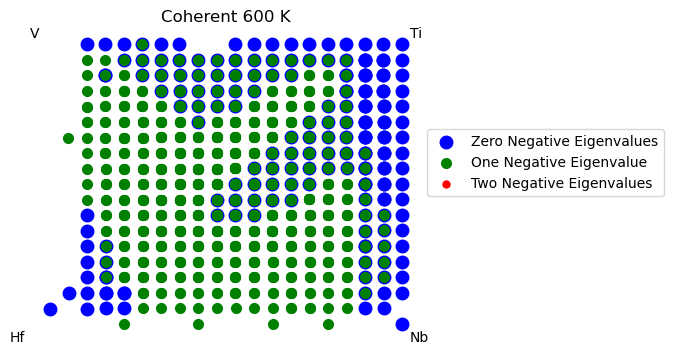

In [17]:
# Here is Brent's affine transformation code with n = 4. I commented out a lot that I didn't need
from matplotlib.patches import Polygon


def generate_regular_pentagon(radius=.5, center=(0, 0), rotation_angle=0):
    """
    Generate vertices of a regular pentagon and rotate it by a given angle.

    Parameters:
    - radius: The radius of the circumscribed circle.
    - center: The center of the pentagon.
    - rotation_angle: Rotation angle in radians.

    Returns:
    - vertices: List of vertices of the regular pentagon.
    """
    n = 4
    # Adjust the starting angle by π/5 to make one side flat on the horizontal
    angles = np.linspace(np.pi / 5, 2 * np.pi + np.pi / 5, n, endpoint=False)

    # Rotate the pentagon by the given rotation_angle
    angles += rotation_angle

    vertices = np.array([[center[0] + radius * np.cos(angle),
                          center[1] + radius * np.sin(angle)] for angle in angles])
    return vertices


def barycentric_to_cartesian(barycentric_coords, vertices):
    """
    Convert barycentric coordinates to Cartesian coordinates.

    Parameters:
    - barycentric_coords: Barycentric coordinates for each point.
    - vertices: Vertices of the polygon.

    Returns:
    - Cartesian coordinates of the points.
    """
    return np.dot(barycentric_coords, vertices)


def plot_pentagon_with_barycentric_projection(Q, barycentric_coords):
    """
    Plot the regular pentagon and barycentric coordinates.

    Parameters:
    - Q: List of vertices of the regular pentagon.
    - barycentric_coords: Barycentric coordinates of points.
    """
    #fig, ax = plt.subplots()

    # # Create the pentagon
    # polygon = Polygon(Q, closed=True, edgecolor='k', facecolor='lightgray')
    # ax.add_patch(polygon)
    #
    # # Plot the vertices
    # Q = np.array(Q)
    # ax.scatter(Q[:, 0], Q[:, 1], c='blue', label='Vertices')

    # Convert barycentric coordinates to Cartesian coordinates
    cartesian_coords = barycentric_to_cartesian(barycentric_coords, Q)

    return cartesian_coords


#for n in np.linspace(0,2,100):
n = .952
# Example usage
# Set a rotation angle (in radians). For example, np.pi/4 for 45 degrees
rotation_angle = np.pi / n  # 30 degrees

Q = generate_regular_pentagon(radius=1, center=(0, 0), rotation_angle=rotation_angle)



# comps2 has the new projected coords
elements = ['Hf','Nb','Ti','V']
comps2 = plot_pentagon_with_barycentric_projection(Q, eig_dataset[elements])

eig_dataset['proj0'] = comps2[:, 0]
eig_dataset['proj1'] = comps2[:, 1]

# Here I am breaking up the points into their discrete categories so they can be plotted separately (had to do this for the legend to work right)
comps_0_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues']==0]
comps_1_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues']==1]
comps_2_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues']==2]

# Plot the projections
plt.figure(figsize=(5,4))

plt.scatter(comps_0_neg_1500['proj0'],comps_0_neg_1500['proj1'],color='blue',label='Zero Negative Eigenvalues',s=81)
plt.scatter(comps_1_neg_1500['proj0'],comps_1_neg_1500['proj1'],color='green',label='One Negative Eigenvalue',s=49)
plt.scatter(comps_2_neg_1500['proj0'],comps_2_neg_1500['proj1'],color='red',label='Two Negative Eigenvalues',s=25)

plt.title('Coherent 600 K')
plt.axis('off')
plt.figtext(0.08,0.1, 'Hf')
plt.figtext(0.88,0.1, 'Nb')
plt.figtext(0.88,0.86, 'Ti')
plt.figtext(0.12,0.86, 'V')
plt.legend(bbox_to_anchor=(1,0.7))
#plt.savefig('coherent_600_inverse.pdf', bbox_inches = "tight")
#plt.savefig('coherent_1000_diff_sizes.pdf', bbox_inches = "tight")

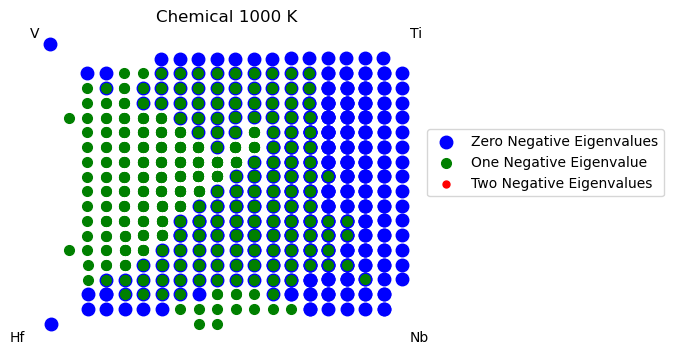

In [7]:
elements = ['Hf','Nb','Ti','V']
comps2 = plot_pentagon_with_barycentric_projection(Q, eig_dataset[elements])

eig_dataset['proj0'] = comps2[:, 0]
eig_dataset['proj1'] = comps2[:, 1]

# Here I am breaking up the points into their discrete categories so they can be plotted separately (had to do this for the legend to work right)
comps_0_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues_chem']==0]
comps_1_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues_chem']==1]
comps_2_neg_1500 = eig_dataset[eig_dataset['Negative Eigenvalues_chem']==2]

# Plot the projections
plt.figure(figsize=(5,4))

plt.scatter(comps_0_neg_1500['proj0'],comps_0_neg_1500['proj1'],color='blue',label='Zero Negative Eigenvalues',s=81)
plt.scatter(comps_1_neg_1500['proj0'],comps_1_neg_1500['proj1'],color='green',label='One Negative Eigenvalue',s=49)
plt.scatter(comps_2_neg_1500['proj0'],comps_2_neg_1500['proj1'],color='red',label='Two Negative Eigenvalues',s=25)


#plt.title('T = 600 K')
plt.title('Chemical 1000 K')
plt.axis('off')
plt.figtext(0.08,0.1, 'Hf')
plt.figtext(0.88,0.1, 'Nb')
plt.figtext(0.88,0.86, 'Ti')
plt.figtext(0.12,0.86, 'V')
plt.legend(bbox_to_anchor=(1,0.7))
#plt.savefig('chemical_1000_diff_sizes.pdf', bbox_inches = "tight")

In [13]:
# Eigenvalue plots; all the same process, but at different compositions specified in the Workspace
# M, eta, and lattice parameter also have to be adjusted along with composition since they are functions of composition; can be pulled from excel sheet
wks = Workspace(database=Database('HfNbVTi.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): 0.25,v.X('NB'): 0.25, v.X('TI'): 0.25, v.T: (300,2000,50), v.P: 101325})
dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI

eta = np.array([[0.08620911, 0.07105138, 0.06485024]])

M = 149.323894513184*1e9
lattice_param = 3.2726
#V=a^3*N_A/2
V = (lattice_param*1e-10)**3*6.022e23/2
#coherent contribution
coherent_Hessian = 2*M*V*(eta.reshape(-1,1)@eta)

chem_Hessian_list = []
coherent_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]]))
    coherent_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]])+coherent_Hessian)

O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
chem_orthogonal_Hessian_list = []
coherent_orthogonal_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_orthogonal_Hessian_list.append(O.T@chem_Hessian_list[i]@O)
    coherent_orthogonal_Hessian_list.append(O.T@coherent_Hessian_list[i]@O)

chem_eigenvalues_list = []
chem_eigenvectors_list = []
coherent_eigenvalues_list = []
coherent_eigenvectors_list = []
for i in range(len(d2G_dxHFdxHF)):
    values, vectors = np.linalg.eig(chem_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    chem_eigenvalues_list.append(sorted)
    chem_eigenvectors_list.append(vectors)
    values, vectors = np.linalg.eig(coherent_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    coherent_eigenvalues_list.append(sorted)
    coherent_eigenvectors_list.append(vectors)

chem_transformed_eigenvector1 = []
coherent_transformed_eigenvector1 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector1.append(O@chem_eigenvectors_list[i][:,0])
    coherent_transformed_eigenvector1.append(O@coherent_eigenvectors_list[i][:,0])

chem_transformed_eigenvector2 = []
coherent_transformed_eigenvector2 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector2.append(O@chem_eigenvectors_list[i][:,1])
    coherent_transformed_eigenvector2.append(O@coherent_eigenvectors_list[i][:,1])

chem_transformed_eigenvector3 = []
coherent_transformed_eigenvector3 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector3.append(O@chem_eigenvectors_list[i][:,2])
    coherent_transformed_eigenvector3.append(O@coherent_eigenvectors_list[i][:,2])

C:\Users\Courtney\kunselman_dot_derivatives_update\pycalphad\pycalphad\io\tdb.py:995: UserWarning: The type definition character `%` was defined in the following phases: ['BCC_A2', 'HCP_A3'], but no corresponding TYPE_DEFINITION line was found in the TDB.
  warnings.warn(f"The type definition character `{typechar}` was defined in the following phases: "


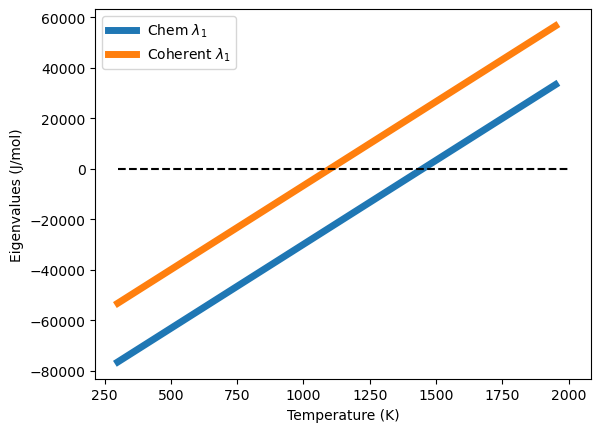

In [14]:
temps = np.arange(300,2000,50)

plt.figure(0)
plt.plot(temps, np.array(chem_eigenvalues_list)[:,0],label='Chem $\lambda_1$',linewidth=5)
plt.plot(temps, np.array(coherent_eigenvalues_list)[:,0],label='Coherent $\lambda_1$',linewidth=5)
plt.plot([300,2000],[0,0],color='black',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('Eigenvalues (J/mol)')
plt.legend()
#plt.savefig('eigenvalues_Hf25.pdf', bbox_inches = "tight")

In [138]:
wks = Workspace(database=Database('HfNbVTi.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): 0.1,v.X('NB'): 0.4, v.X('TI'): 0.4, v.T: (300,2000,50), v.P: 101325})
dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI

eta = np.array([[0.03720351, 0.05484124, 0.05273471]])

M = 142.988156*1e9
lattice_param = 3.2702
#V=a^3*N_A/2
V = (lattice_param*1e-10)**3*6.022e23/2
#coherent contribution
coherent_Hessian = 2*M*V*(eta.reshape(-1,1)@eta)

chem_Hessian_list = []
coherent_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]]))
    coherent_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]])+coherent_Hessian)

O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
chem_orthogonal_Hessian_list = []
coherent_orthogonal_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_orthogonal_Hessian_list.append(O.T@chem_Hessian_list[i]@O)
    coherent_orthogonal_Hessian_list.append(O.T@coherent_Hessian_list[i]@O)

chem_eigenvalues_list = []
chem_eigenvectors_list = []
coherent_eigenvalues_list = []
coherent_eigenvectors_list = []
for i in range(len(d2G_dxHFdxHF)):
    values, vectors = np.linalg.eig(chem_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    chem_eigenvalues_list.append(sorted)
    chem_eigenvectors_list.append(vectors)
    values, vectors = np.linalg.eig(coherent_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    coherent_eigenvalues_list.append(sorted)
    coherent_eigenvectors_list.append(vectors)

chem_transformed_eigenvector1 = []
coherent_transformed_eigenvector1 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector1.append(O@chem_eigenvectors_list[i][:,0])
    coherent_transformed_eigenvector1.append(O@coherent_eigenvectors_list[i][:,0])

chem_transformed_eigenvector2 = []
coherent_transformed_eigenvector2 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector2.append(O@chem_eigenvectors_list[i][:,1])
    coherent_transformed_eigenvector2.append(O@coherent_eigenvectors_list[i][:,1])

chem_transformed_eigenvector3 = []
coherent_transformed_eigenvector3 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector3.append(O@chem_eigenvectors_list[i][:,2])
    coherent_transformed_eigenvector3.append(O@coherent_eigenvectors_list[i][:,2])

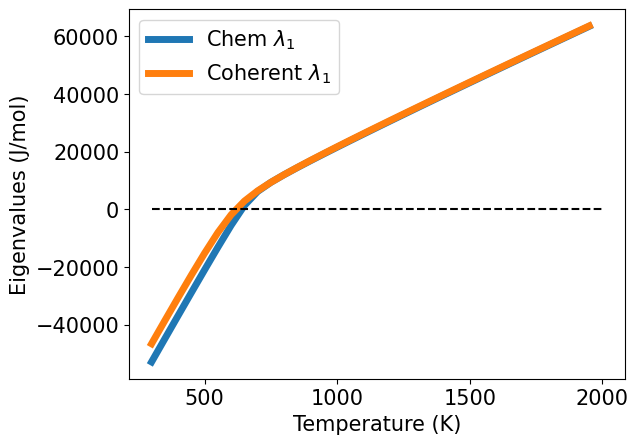

In [140]:
temps = np.arange(300,2000,50)

plt.figure(0)
plt.plot(temps, np.array(chem_eigenvalues_list)[:,0],label='Chem $\lambda_1$',linewidth=5)
plt.plot(temps, np.array(coherent_eigenvalues_list)[:,0],label='Coherent $\lambda_1$',linewidth=5)
plt.plot([300,2000],[0,0],color='black',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('Eigenvalues (J/mol)')
plt.legend()
plt.savefig('eigenvalues_Hf1.pdf', bbox_inches = "tight")

In [143]:
wks = Workspace(database=Database('HfNbVTi.tdb'), components=['HF', 'NB', 'TI', 'V'], phases=['BCC_A2'],
                 conditions={v.X('HF'): 0.6,v.X('NB'): 0.1, v.X('TI'): 0.1, v.T: (300,2000,50), v.P: 101325})
dmuHF_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(HF)'))
dmuNB_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(HF)'))
dmuTI_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(HF)'))
dmuV_dxHF = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(HF)'))

dmuHF_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(NB)'))
dmuNB_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(NB)'))
dmuTI_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(NB)'))
dmuV_dxNB = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(NB)'))

dmuHF_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(HF).X(TI)'))
dmuNB_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(NB).X(TI)'))
dmuTI_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(TI).X(TI)'))
dmuV_dxTI = wks.get(IsolatedPhase('BCC_A2',wks=wks)('MU(V).X(TI)'))

d2G_dxHFdxHF = dmuHF_dxHF - dmuV_dxHF
d2G_dxHFdxNB = dmuNB_dxHF - dmuV_dxHF
d2G_dxHFdxTI = dmuTI_dxHF - dmuV_dxHF

d2G_dxNBdxHF = dmuHF_dxNB - dmuV_dxNB
d2G_dxNBdxNB = dmuNB_dxNB - dmuV_dxNB
d2G_dxNBdxTI = dmuTI_dxNB - dmuV_dxNB

d2G_dxTIdxHF = dmuHF_dxTI - dmuV_dxTI
d2G_dxTIdxNB = dmuNB_dxTI - dmuV_dxTI
d2G_dxTIdxTI = dmuTI_dxTI - dmuV_dxTI

eta = np.array([[0.12660562, 0.08260484, 0.07816819]])

M = 161.764907*1e9
lattice_param = 3.3828
#V=a^3*N_A/2
V = (lattice_param*1e-10)**3*6.022e23/2
#coherent contribution
coherent_Hessian = 2*M*V*(eta.reshape(-1,1)@eta)

chem_Hessian_list = []
coherent_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]]))
    coherent_Hessian_list.append(np.array([[d2G_dxHFdxHF[i], d2G_dxHFdxNB[i], d2G_dxHFdxTI[i]], [d2G_dxNBdxHF[i], d2G_dxNBdxNB[i], d2G_dxNBdxTI[i]], [d2G_dxTIdxHF[i], d2G_dxTIdxNB[i], d2G_dxTIdxTI[i]]])+coherent_Hessian)

O = np.array([[-1, -1/np.sqrt(3), -1/np.sqrt(6)],[1, -1/np.sqrt(3), -1/np.sqrt(6)],[0, 2/np.sqrt(3), -1/np.sqrt(6)]])
chem_orthogonal_Hessian_list = []
coherent_orthogonal_Hessian_list = []
for i in range(len(d2G_dxHFdxHF)):
    chem_orthogonal_Hessian_list.append(O.T@chem_Hessian_list[i]@O)
    coherent_orthogonal_Hessian_list.append(O.T@coherent_Hessian_list[i]@O)

chem_eigenvalues_list = []
chem_eigenvectors_list = []
coherent_eigenvalues_list = []
coherent_eigenvectors_list = []
for i in range(len(d2G_dxHFdxHF)):
    values, vectors = np.linalg.eig(chem_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    chem_eigenvalues_list.append(sorted)
    chem_eigenvectors_list.append(vectors)
    values, vectors = np.linalg.eig(coherent_orthogonal_Hessian_list[i])
    sorted = np.sort(values)
    coherent_eigenvalues_list.append(sorted)
    coherent_eigenvectors_list.append(vectors)

chem_transformed_eigenvector1 = []
coherent_transformed_eigenvector1 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector1.append(O@chem_eigenvectors_list[i][:,0])
    coherent_transformed_eigenvector1.append(O@coherent_eigenvectors_list[i][:,0])

chem_transformed_eigenvector2 = []
coherent_transformed_eigenvector2 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector2.append(O@chem_eigenvectors_list[i][:,1])
    coherent_transformed_eigenvector2.append(O@coherent_eigenvectors_list[i][:,1])

chem_transformed_eigenvector3 = []
coherent_transformed_eigenvector3 = []
for i in range(len(d2G_dxHFdxHF)):
    chem_transformed_eigenvector3.append(O@chem_eigenvectors_list[i][:,2])
    coherent_transformed_eigenvector3.append(O@coherent_eigenvectors_list[i][:,2])

C:\Users\Courtney\kunselman_dot_derivatives_update\pycalphad\pycalphad\io\tdb.py:995: UserWarning: The type definition character `%` was defined in the following phases: ['BCC_A2', 'HCP_A3'], but no corresponding TYPE_DEFINITION line was found in the TDB.
  warnings.warn(f"The type definition character `{typechar}` was defined in the following phases: "


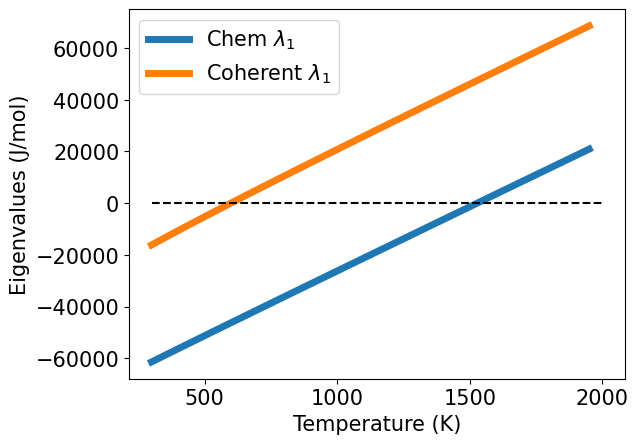

In [145]:
temps = np.arange(300,2000,50)

plt.figure(0)
plt.plot(temps, np.array(chem_eigenvalues_list)[:,0],label='Chem $\lambda_1$',linewidth=5)
plt.plot(temps, np.array(coherent_eigenvalues_list)[:,0],label='Coherent $\lambda_1$',linewidth=5)
plt.plot([300,2000],[0,0],color='black',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('Eigenvalues (J/mol)')
plt.legend()
plt.savefig('eigenvalues_Hf4.pdf', bbox_inches = "tight")

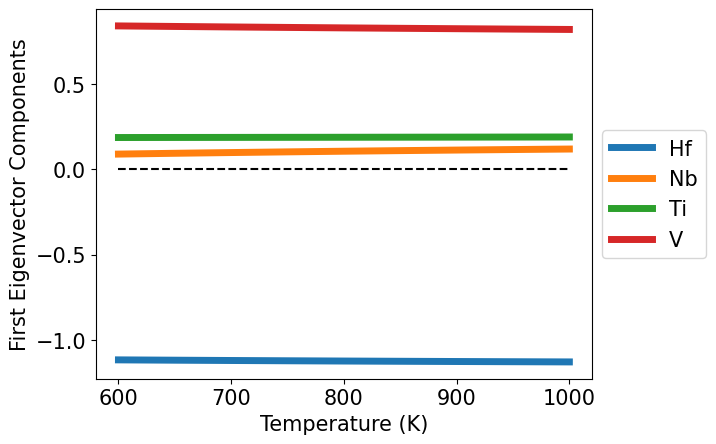

In [129]:
# Eigenvector plot for chemical Hessian at the same composition as the eigenvalue plot above
temps = np.arange(600,1050,50)

plt.rc('font',size=15)

plt.figure(1)
plt.plot(temps, np.array(chem_transformed_eigenvector1)[:,0], label='Hf',linewidth=5)
plt.plot(temps, np.array(chem_transformed_eigenvector1)[:,1], label='Nb',linewidth=5)
plt.plot(temps, np.array(chem_transformed_eigenvector1)[:,2], label='Ti',linewidth=5)
plt.plot(temps, - np.array(chem_transformed_eigenvector1)[:,1] - np.array(chem_transformed_eigenvector1)[:,0] - np.array(chem_transformed_eigenvector1)[:,2], label='V',linewidth=5)
plt.plot([600,1000],[0,0],color='black',linestyle='dashed')
#plt.plot([1200,1200],[-1.25,1],color='red',linestyle='dashed')
plt.xlabel('Temperature (K)')
plt.ylabel('First Eigenvector Components')
plt.legend(bbox_to_anchor=(1,0.7))
plt.savefig('eigenvector.pdf', bbox_inches = "tight")
